# OPE-4 | Q3: Audio Filtering (Low-Pass and Band-Pass)
**Subject:** Digital Signal and Image Processing (01CT1513)

* **Q3(a)** Low-pass filter a song at three different cutoff frequencies and compare the results.
* **Q3(b)** Use a band-pass filter to suppress the background music (keep vocals) and its complement to suppress the vocals (keep the background music). Each result is saved as its own MP3.

**How to run in VS Code:** install the *Python* and *Jupyter* extensions, open this file, choose a Python kernel (top right), set `FILENAME` in section 1 to your MP3 path and use **Run All**. The five MP3 files are written to an `output` folder next to this notebook.

## 0. Install and import
The first cell needs to be run only once (it installs the libraries into the selected kernel).

In [1]:
%pip install -q numpy scipy pandas matplotlib librosa soundfile ipykernel

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
from scipy.signal import butter, sosfiltfilt, sosfreqz
from IPython.display import Audio, display

os.makedirs("output", exist_ok=True)

## 1. Load the MP3 song
Set `FILENAME` to the full path of your MP3 file. On Windows use a raw string (`r"..."`) so the backslashes are read correctly. The song is loaded as **mono** at its **original sample rate**.

In [3]:
FILENAME = r"C:\Users\admin\Documents\DSIP\Lab Experiment\OPE 4.mp3"   # <-- change this to your MP3 file

if not os.path.isfile(FILENAME):
    raise FileNotFoundError(f"MP3 not found: {FILENAME}  (edit FILENAME above)")

y, sr = librosa.load(FILENAME, sr=None, mono=True)
print(f"File        : {FILENAME}")
print(f"Sample rate : {sr} Hz")
print(f"Duration    : {len(y)/sr:.2f} s")
print(f"Nyquist     : {sr/2:.0f} Hz")
display(Audio(y, rate=sr))

File        : C:\Users\admin\Documents\DSIP\Lab Experiment\OPE 4.mp3
Sample rate : 48000 Hz
Duration    : 22.46 s
Nyquist     : 24000 Hz


## 2. Helper functions

In [4]:
def lowpass(x, cutoff, fs, order=6):
    sos = butter(order, cutoff, btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x)          # zero-phase (no time shift)

def bandpass(x, low, high, fs, order=6):
    sos = butter(order, [low, high], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

def normalise(x, peak=0.95):
    m = np.max(np.abs(x))
    return x if m == 0 else x / m * peak

def save_mp3(x, fs, name):
    mp3 = f"output/{name}.mp3"
    data = normalise(x)
    try:                                   # 1st choice: libsndfile MP3 writer (no extra install)
        sf.write(mp3, data, fs, format="MP3")
    except Exception:                      # fallback: ffmpeg (must be installed and on PATH)
        wav = f"output/{name}.wav"
        sf.write(wav, data, fs)
        try:
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", wav,
                            "-codec:a", "libmp3lame", "-b:a", "192k", mp3], check=True)
        except FileNotFoundError:
            raise RuntimeError("Cannot write MP3. Run 'pip install -U soundfile' or install ffmpeg.")
        finally:
            if os.path.exists(wav): os.remove(wav)
    print("saved ->", os.path.abspath(mp3))

def plot_spec(x, fs, title):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(x)), ref=np.max)
    plt.figure(figsize=(10, 3.8))
    librosa.display.specshow(D, sr=fs, x_axis="time", y_axis="hz", cmap="magma")
    plt.colorbar(format="%+2.0f dB"); plt.title(title)
    plt.xlabel("Time (s)"); plt.ylabel("Frequency (Hz)")
    plt.tight_layout(); plt.show()

def metrics(x, fs, ref):
    return {
        "RMS level": float(np.sqrt(np.mean(x**2))),
        "Energy kept (%)": 100 * float(np.sum(x**2) / np.sum(ref**2)),
        "Spectral centroid (Hz)": float(np.mean(librosa.feature.spectral_centroid(y=x, sr=fs))),
        "95% energy below (Hz)": float(np.mean(librosa.feature.spectral_rolloff(y=x, sr=fs, roll_percent=0.95))),
    }

## 3. Original song: spectrum and spectrogram
The spectrogram shows how the song's energy is spread over frequency and time.

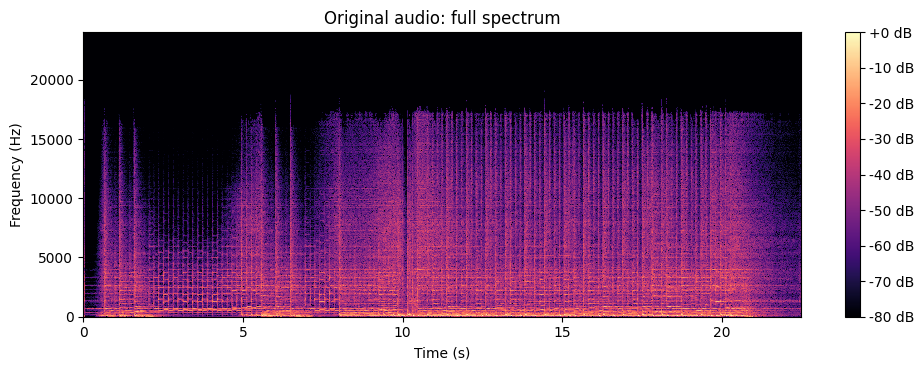

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


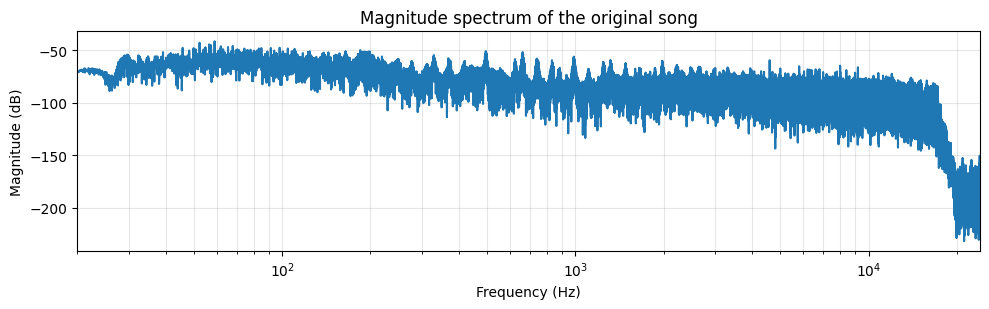

In [5]:
plot_spec(y, sr, "Original audio: full spectrum")

f = np.fft.rfftfreq(len(y), 1/sr)
mag = np.abs(np.fft.rfft(y)) / len(y)
plt.figure(figsize=(10, 3.2))
plt.semilogx(f[1:], 20*np.log10(mag[1:] + 1e-12))
plt.xlim(20, sr/2); plt.grid(True, which="both", alpha=.3)
plt.title("Magnitude spectrum of the original song")
plt.xlabel("Frequency (Hz)"); plt.ylabel("Magnitude (dB)")
plt.tight_layout(); plt.show()

## Q3(a) Low-pass filter with three cutoff frequencies
A 6th-order **Butterworth** low-pass filter is designed with `scipy.signal.butter`. The cutoffs chosen are:

| Cutoff | Expected character |
|---|---|
| 500 Hz | Very muffled: only bass and the lowest part of the voice remain |
| 2000 Hz | Telephone-like / dull: vowels remain, brightness and consonants are lost |
| 5000 Hz | Close to the original: only the "air" and cymbal detail are removed |

You can change the list `CUTOFFS` to try other values.

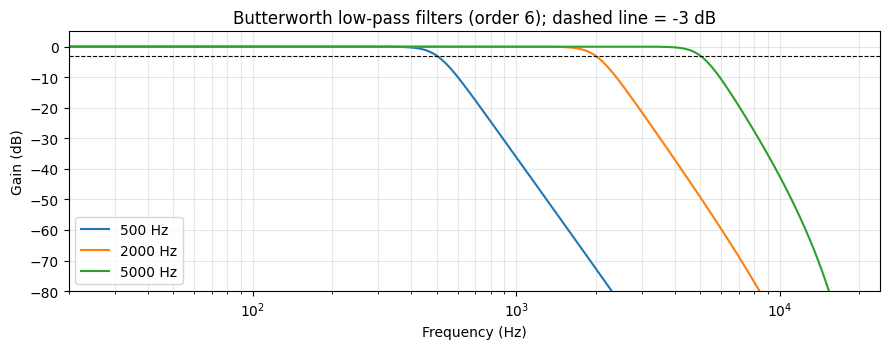

In [6]:
CUTOFFS = [500, 2000, 5000]   # Hz
ORDER = 6

# Frequency response of the three designed filters
plt.figure(figsize=(9, 3.6))
for fc in CUTOFFS:
    sos = butter(ORDER, fc, btype="low", fs=sr, output="sos")
    w, h = sosfreqz(sos, worN=8192, fs=sr)
    plt.semilogx(w[1:], 20*np.log10(np.abs(h[1:]) + 1e-9), label=f"{fc} Hz")
plt.ylim(-80, 5); plt.xlim(20, sr/2); plt.grid(True, which="both", alpha=.3)
plt.axhline(-3, color="k", ls="--", lw=.8)
plt.title(f"Butterworth low-pass filters (order {ORDER}); dashed line = -3 dB")
plt.xlabel("Frequency (Hz)"); plt.ylabel("Gain (dB)"); plt.legend()
plt.tight_layout(); plt.show()


--- Low-pass, cutoff = 500 Hz ---


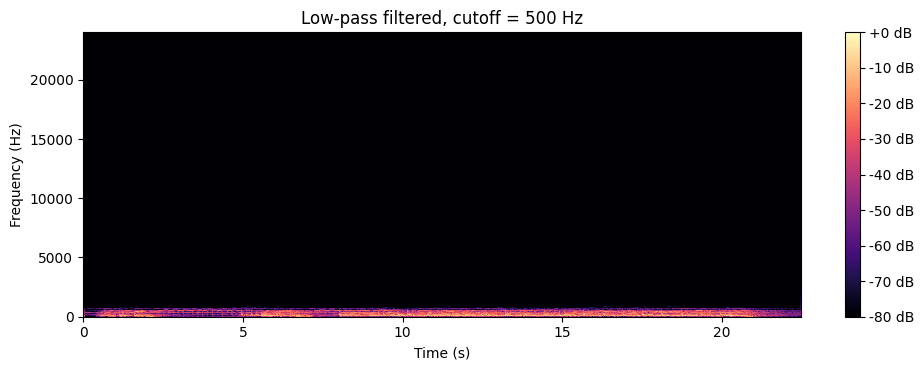

saved -> c:\Users\admin\Documents\DSIP\Lab Experiment\output\lowpass_500Hz.mp3

--- Low-pass, cutoff = 2000 Hz ---


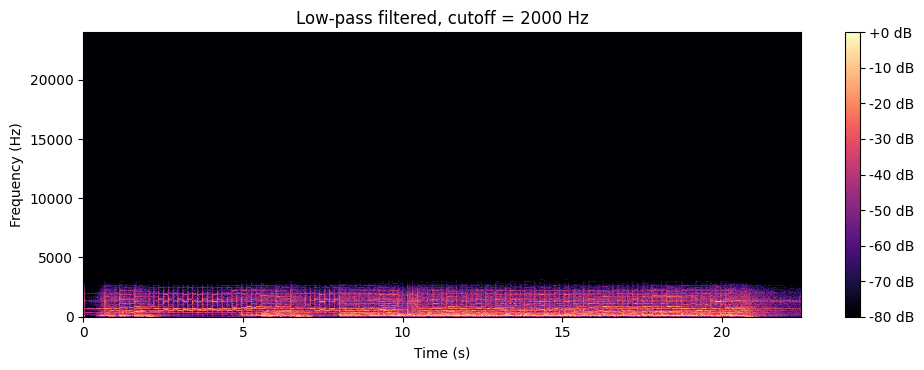

saved -> c:\Users\admin\Documents\DSIP\Lab Experiment\output\lowpass_2000Hz.mp3

--- Low-pass, cutoff = 5000 Hz ---


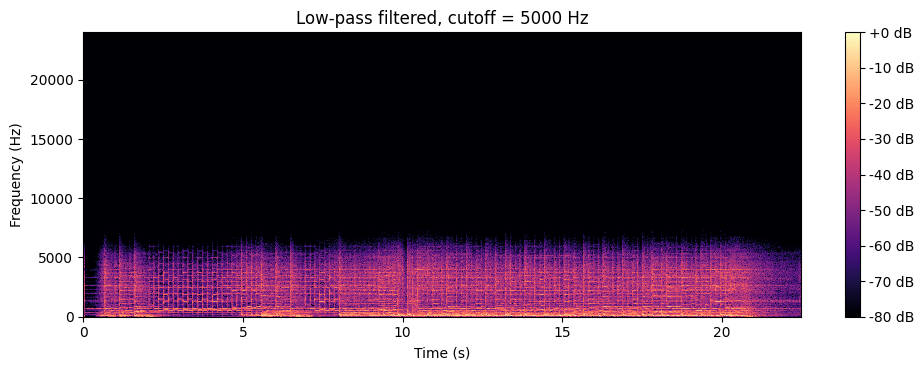

saved -> c:\Users\admin\Documents\DSIP\Lab Experiment\output\lowpass_5000Hz.mp3


In [7]:
lp = {}
for fc in CUTOFFS:
    lp[fc] = lowpass(y, fc, sr, ORDER)
    print(f"\n--- Low-pass, cutoff = {fc} Hz ---")
    display(Audio(lp[fc], rate=sr))
    plot_spec(lp[fc], sr, f"Low-pass filtered, cutoff = {fc} Hz")
    save_mp3(lp[fc], sr, f"lowpass_{fc}Hz")

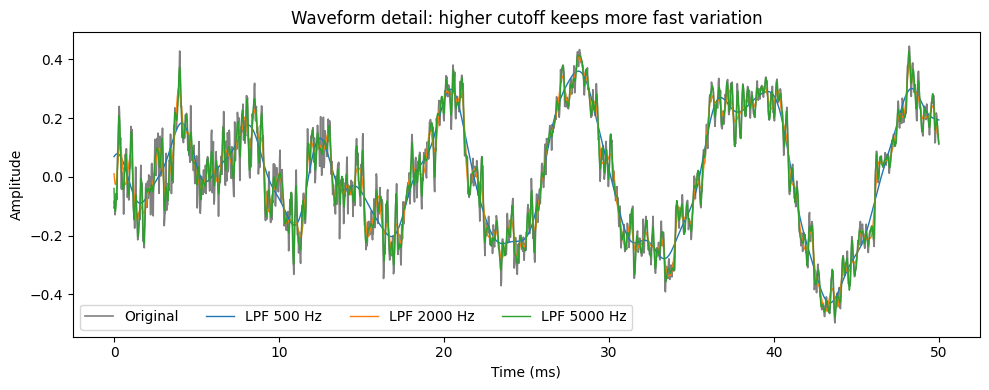

In [8]:
# Waveform comparison (a short 0.05 s window from the middle of the song)
mid = len(y)//2
n = int(0.05*sr)
t = np.arange(n)/sr*1000
plt.figure(figsize=(10, 4))
plt.plot(t, y[mid:mid+n], label="Original", lw=1.2, color="grey")
for fc in CUTOFFS:
    plt.plot(t, lp[fc][mid:mid+n], label=f"LPF {fc} Hz", lw=1)
plt.title("Waveform detail: higher cutoff keeps more fast variation")
plt.xlabel("Time (ms)"); plt.ylabel("Amplitude"); plt.legend(ncol=4)
plt.tight_layout(); plt.show()

In [9]:
# Numerical comparison table (copy this into the observation table of the report)
rows = {"Original": metrics(y, sr, y)}
for fc in CUTOFFS:
    rows[f"LPF {fc} Hz"] = metrics(lp[fc], sr, y)
table_a = pd.DataFrame(rows).T.round(3)
display(table_a)

,RMS level,Energy kept (%),Spectral centroid (Hz),95% energy below (Hz)
Original,0.123,100.000,3163.154,10372.657
LPF 500 Hz,0.106,73.574,211.249,485.680
LPF 2000 Hz,0.116,89.260,649.350,1828.270
LPF 5000 Hz,0.121,96.924,1495.144,4233.823


## Q3(b) Band-pass filtering: suppress background music / suppress vocals
The main energy of the human voice (fundamentals and the vowel formants that carry speech and singing) lies roughly between **300 Hz and 3400 Hz**. Therefore:

1. **Vocals kept, background suppressed:** a **band-pass** filter, 300 to 3400 Hz.
2. **Background kept, vocals suppressed:** the **complement** of that band, i.e. original minus the band-pass output. This is equivalent to a band-stop filter over the vocal band, and keeps the bass and drums below 300 Hz and the hi-hats, cymbals and "air" above 3400 Hz.

Because the voice and many instruments (guitar, keyboard, strings) share the same frequencies, this is only an **approximate** separation.

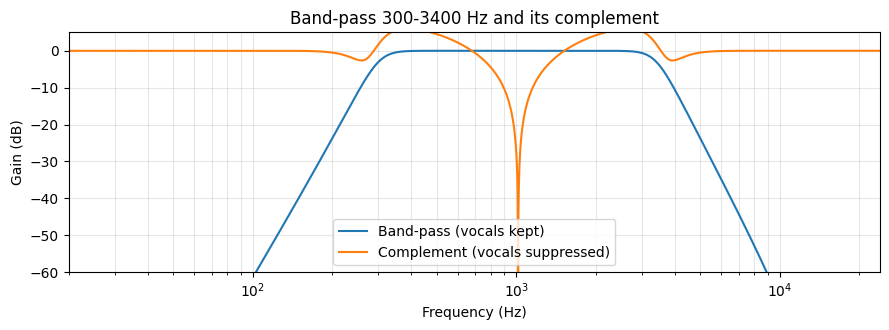

In [10]:
VOC_LOW, VOC_HIGH = 300, 3400     # Hz
ORDER_BP = 6

vocals_kept = bandpass(y, VOC_LOW, VOC_HIGH, sr, ORDER_BP)    # background suppressed
background_kept = y - vocals_kept                              # vocals suppressed

sos = butter(ORDER_BP, [VOC_LOW, VOC_HIGH], btype="band", fs=sr, output="sos")
w, h = sosfreqz(sos, worN=8192, fs=sr)
plt.figure(figsize=(9, 3.4))
plt.semilogx(w[1:], 20*np.log10(np.abs(h[1:]) + 1e-9), label="Band-pass (vocals kept)")
plt.semilogx(w[1:], 20*np.log10(np.abs(1 - h[1:]) + 1e-9), label="Complement (vocals suppressed)")
plt.ylim(-60, 5); plt.xlim(20, sr/2); plt.grid(True, which="both", alpha=.3)
plt.title(f"Band-pass {VOC_LOW}-{VOC_HIGH} Hz and its complement")
plt.xlabel("Frequency (Hz)"); plt.ylabel("Gain (dB)"); plt.legend()
plt.tight_layout(); plt.show()

1) Background music suppressed (vocal band kept)


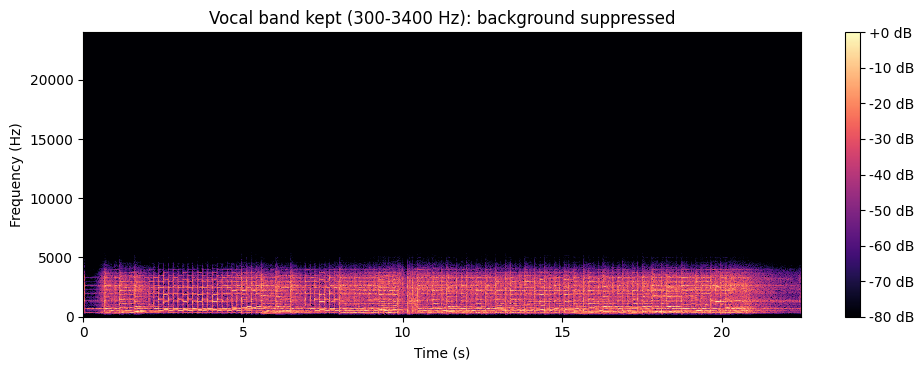

saved -> c:\Users\admin\Documents\DSIP\Lab Experiment\output\vocals_only_bandpass.mp3

2) Vocals suppressed (background kept)


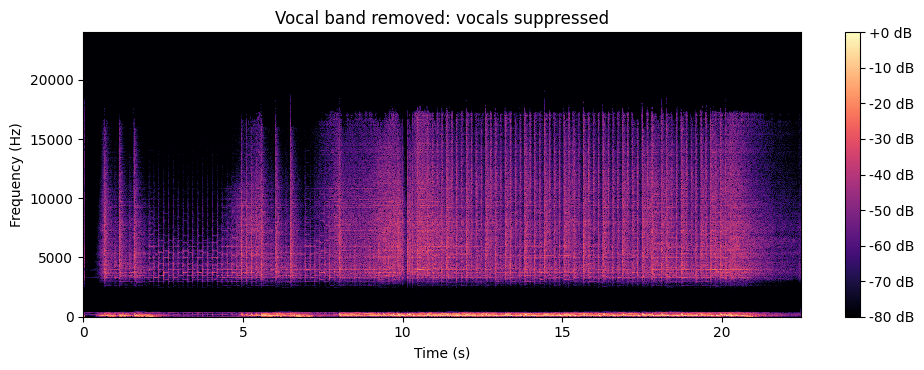

saved -> c:\Users\admin\Documents\DSIP\Lab Experiment\output\background_only.mp3


In [11]:
print("1) Background music suppressed (vocal band kept)")
display(Audio(vocals_kept, rate=sr))
plot_spec(vocals_kept, sr, f"Vocal band kept ({VOC_LOW}-{VOC_HIGH} Hz): background suppressed")
save_mp3(vocals_kept, sr, "vocals_only_bandpass")

print("\n2) Vocals suppressed (background kept)")
display(Audio(background_kept, rate=sr))
plot_spec(background_kept, sr, "Vocal band removed: vocals suppressed")
save_mp3(background_kept, sr, "background_only")

In [12]:
rows = {
    "Original": metrics(y, sr, y),
    f"Band-pass {VOC_LOW}-{VOC_HIGH} Hz (vocals kept)": metrics(vocals_kept, sr, y),
    "Complement (vocals suppressed)": metrics(background_kept, sr, y),
}
table_b = pd.DataFrame(rows).T.round(3)
display(table_b)

,RMS level,Energy kept (%),Spectral centroid (Hz),95% energy below (Hz)
Original,0.123,100.000,3163.154,10372.657
Band-pass 300-3400 Hz (vocals kept),0.061,24.579,1540.914,3242.251
Complement (vocals suppressed),0.105,73.229,4508.804,12092.526


,Original,Vocals kept,Vocals suppressed
Below 300 Hz (bass),69.080002,0.17,93.75
300-3400 Hz (vocal band),26.020000,99.45,0.34
Above 3400 Hz (treble),4.900000,0.38,5.91


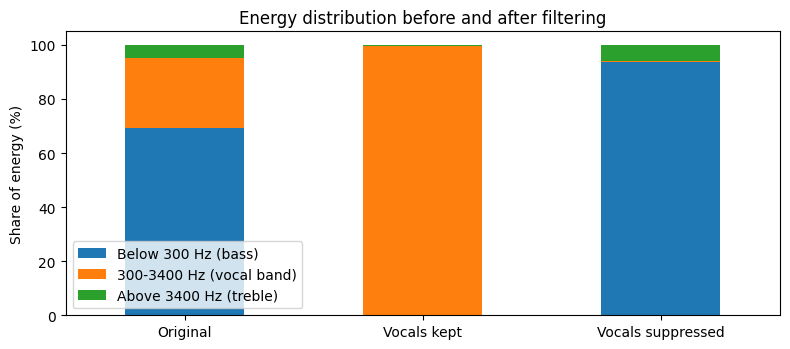

In [13]:
# Where does the energy go? Energy share of the three regions of the spectrum.
def band_energy(x, lo, hi):
    X = np.abs(np.fft.rfft(x))**2
    f = np.fft.rfftfreq(len(x), 1/sr)
    return 100 * X[(f >= lo) & (f < hi)].sum() / X.sum()

regions = [("Below 300 Hz (bass)", 0, 300),
           ("300-3400 Hz (vocal band)", 300, 3400),
           ("Above 3400 Hz (treble)", 3400, sr/2)]
share = pd.DataFrame({
    "Original": [band_energy(y, a, b) for _, a, b in regions],
    "Vocals kept": [band_energy(vocals_kept, a, b) for _, a, b in regions],
    "Vocals suppressed": [band_energy(background_kept, a, b) for _, a, b in regions],
}, index=[r[0] for r in regions]).round(2)
display(share)
share.T.plot(kind="bar", stacked=True, figsize=(8, 3.6), rot=0)
plt.ylabel("Share of energy (%)"); plt.title("Energy distribution before and after filtering")
plt.tight_layout(); plt.show()

## 4. Saved MP3 files

In [14]:
print("Folder:", os.path.abspath("output"))
for f in sorted(os.listdir("output")):
    print(" -", f, f"({os.path.getsize(os.path.join('output', f))/1024:.0f} KB)")

Folder: c:\Users\admin\Documents\DSIP\Lab Experiment\output
 - background_only.mp3 (317 KB)
 - lowpass_2000Hz.mp3 (156 KB)
 - lowpass_5000Hz.mp3 (187 KB)
 - lowpass_500Hz.mp3 (89 KB)
 - vocals_only_bandpass.mp3 (180 KB)


## 5. Notes for the observations
* Lower cutoff: the sound becomes darker, muffled and less clear because consonants (s, t, k) and cymbals live above 2-4 kHz.
* Higher cutoff: the sound approaches the original and only the highest "sparkle" is lost.
* Band-pass 300-3400 Hz sounds thin and "radio / telephone-like": the bass and the highest treble are gone but the lead voice stays clear.
* The complement keeps bass, drums and treble, and the vocal body is weaker, but the vocals are **not removed completely** because instruments overlap the same band.